# PINN correction of the Joukowski map: unit disk $\to$ exterior of an upper semicircular arc

We seek a meromorphic conformal map from the unit disk (with a pole at the origin, corresponding to $\infty$ in the image) to the complement of the **upper unit semicircular arc**.

The base map is the Joukowski map
\[
J(\zeta)=\frac12\left(\zeta+\frac1\zeta\right),
\]
which maps $|\zeta|=1$ onto the slit $[-1,1]$ and has the correct simple pole at $\zeta=0$.

We therefore learn only a regular correction,
\[
f_\theta(\zeta)=J(\zeta)+h_\theta(\zeta),\qquad
h_\theta(\zeta)=c_\theta\,(\zeta^2-1)\,N_\theta(\zeta).
\]
The factor $(\zeta^2-1)$ vanishes at $\zeta=\pm1$, so $f(\pm1)=J(\pm1)=\pm1$ without a heavy endpoint penalty; near $\zeta=0$ the correction is still $\mathcal O(1)$ because $J$ already carries the pole.

## Important correction to the previous notebook
The boundary of the target is the semicircular **arc itself**, with two sides.  Hence we should **not prescribe a pointwise parameterisation** such as $(\cos t,|\sin t|)$; the correct boundary correspondence is unknown and must be learned.  Instead we impose the geometric boundary conditions
\[
|f_\theta(e^{it})|=1,\qquad \Im f_\theta(e^{it})\ge0,
\]
together with the endpoint normalisation $f(1)=1$, $f(-1)=-1$ and two weak anchor conditions $f(\pm i)\approx i$ to fix the boundary correspondence.

The PINN loss also enforces the Cauchy--Riemann equations in a punctured disk $r_{\min}<|\zeta|<1$ and penalises a small Jacobian to discourage loss of local injectivity.


## Warm-up: simple maps on the unit disk ($|\zeta|<1$)

Same layout as Day~3 exercise: **unit circle with samples** $\leftrightarrow$ **image under $g$**.

1. $z = 2\zeta + 0.4$ (affine): $|\zeta|=1 \mapsto |z - 0.4| = 2$.
2. $z = 1/\zeta$ (inversion): $|\zeta|=1 \mapsto |z|=1$; interior $\mapsto$ $|z|>1$ (pole at $0$).


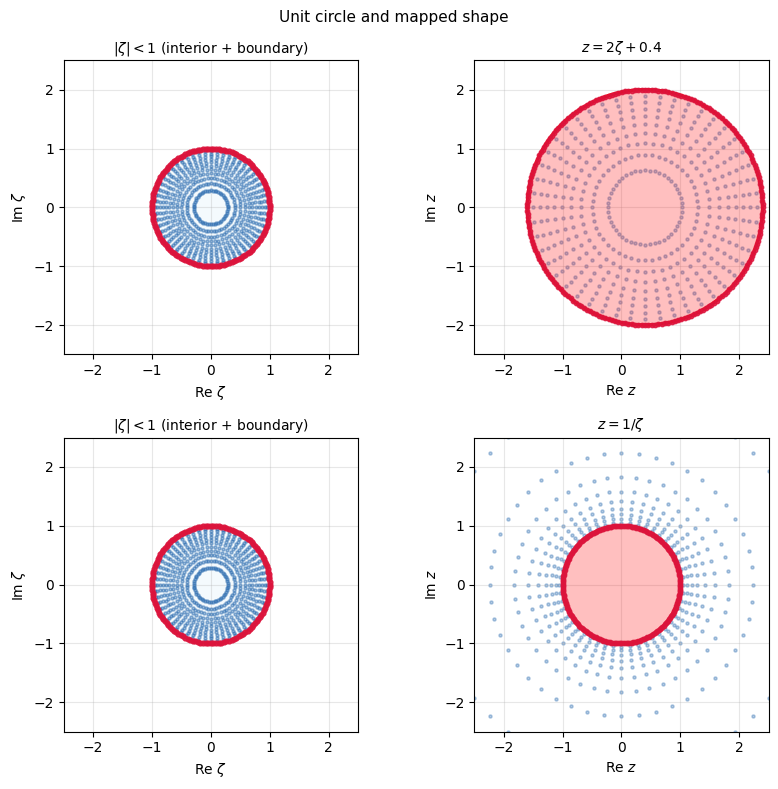

In [21]:
PLOT_LIM = 2.5


def _boundary(n=200):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return np.exp(1j * t)


def _disk_pts(n_r=10, n_t=48):
    u = np.linspace(0, 1, n_r, endpoint=False)
    r = np.sqrt(u)
    t = np.linspace(0, 2 * np.pi, n_t, endpoint=False)
    R, T = np.meshgrid(r, t, indexing="ij")
    z = (R * np.exp(1j * T)).ravel()
    return z[np.abs(z) > 0.08]  # avoid pole for 1/z


def plot_unit_circle(ax, n_boundary=140):
    th = np.linspace(0, 2 * np.pi, 400, endpoint=False)
    zb = _boundary(n_boundary)
    zi = _disk_pts(n_r=12, n_t=56)
    ax.fill(np.cos(th), np.sin(th), color="#e8f4fc", alpha=0.45, zorder=0)
    ax.plot(np.cos(th), np.sin(th), "k-", lw=0.9, alpha=0.7, zorder=1)
    ax.scatter(zi.real, zi.imag, s=5, c="#2b6cb0", alpha=0.45, zorder=2)
    ax.scatter(zb.real, zb.imag, s=12, c="crimson", alpha=0.9, zorder=3)
    ax.set_aspect("equal")
    ax.set_xlim(-PLOT_LIM, PLOT_LIM)
    ax.set_ylim(-PLOT_LIM, PLOT_LIM)
    ax.grid(True, alpha=0.3)
    ax.set_title(r"$|\zeta|<1$ (interior + boundary)", fontsize=10)
    ax.set_xlabel(r"Re $\zeta$")
    ax.set_ylabel(r"Im $\zeta$")


def plot_map_image(ax, g, title):
    zb = _boundary(220)
    wb = g(zb)
    wr, wi = wb.real, wb.imag
    zi = _disk_pts()
    wi_pts = g(zi)
    m = np.isfinite(wi_pts)
    ax.scatter(wi_pts[m].real, wi_pts[m].imag, s=5, c="#2b6cb0", alpha=0.35, zorder=1)
    ax.fill(wr, wi, color="red", alpha=0.25, zorder=2)
    ax.plot(wr, wi, color="red", lw=2.5, zorder=3)
    ax.scatter(wr, wi, s=10, c="crimson", alpha=0.85, zorder=4)
    ax.set_aspect("equal")
    ax.set_xlim(-PLOT_LIM, PLOT_LIM)
    ax.set_ylim(-PLOT_LIM, PLOT_LIM)
    ax.grid(True, alpha=0.3)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(r"Re $z$")
    ax.set_ylabel(r"Im $z$")


g_affine = lambda z: 2 * z + 0.4
g_inv = lambda z: 1.0 / z

fig, axes = plt.subplots(2, 2, figsize=(8.5, 8.0))
plot_unit_circle(axes[0, 0])
plot_map_image(axes[0, 1], g_affine, r"$z=2\zeta+0.4$")
plot_unit_circle(axes[1, 0])
plot_map_image(axes[1, 1], g_inv, r"$z=1/\zeta$")
fig.suptitle("Unit circle and mapped shape", fontsize=11, y=0.98)
plt.tight_layout()
plt.show()


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import torch

torch.set_default_dtype(torch.float64)
np.random.seed(2026)
torch.manual_seed(2026)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


def grad_scalar(y, x):
    return torch.autograd.grad(
        y, x, grad_outputs=torch.ones_like(y),
        create_graph=True, retain_graph=True
    )[0]


class MLP(torch.nn.Module):
    def __init__(self, d_in=2, d_out=2, width=64, depth=4):
        super().__init__()
        layers = [torch.nn.Linear(d_in, width), torch.nn.Tanh()]
        for _ in range(depth - 1):
            layers += [torch.nn.Linear(width, width), torch.nn.Tanh()]
        layers += [torch.nn.Linear(width, d_out)]
        self.net = torch.nn.Sequential(*layers)
        for m in self.modules():
            if isinstance(m, torch.nn.Linear):
                torch.nn.init.xavier_normal_(m.weight)
                torch.nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)


device: cpu


In [14]:
# Training parameters
ADAM_EPOCHS = 18000
LBFGS_STEPS = 400
LR = 8e-4
BC_WARMUP = 3500   # ramp arc/upper weights 0 -> full over this many epochs

N_INT = 1600
N_BND = 800
R_MIN = 0.18       # stay away from Joukowski singularity at 0

WIDTH = 80
DEPTH = 5

# Loss weights (CR-first; endpoints from (z^2-1) factor)
W_CR = 400.0
W_ARC = 350.0
W_UPPER = 350.0
W_END = 0.0
W_ANCHOR = 25.0
W_JAC = 25.0
W_NEG_JAC = 60.0   # penalise folding (jac < 0)
JAC_MIN = 0.04

# Set W_ANCHOR=0 if anchors bias the slit correspondence too strongly.


In [15]:
class JoukowskiCorrectionNet(torch.nn.Module):
    """f(z) = J(z) + c (z^2-1) N(z), with J(z)=(z+1/z)/2."""

    def __init__(self, width=WIDTH, depth=DEPTH):
        super().__init__()
        self.net = MLP(2, 2, width, depth)
        self.raw_c = torch.nn.Parameter(torch.tensor(-1.0, dtype=torch.get_default_dtype()))

    @property
    def c(self):
        return torch.nn.functional.softplus(self.raw_c) + 1e-8

    @staticmethod
    def joukowski(x, y):
        r2 = x*x + y*y
        gx = 0.5 * (x + x/r2)
        gy = 0.5 * (y - y/r2)
        return gx, gy

    def correction(self, xy):
        x, y = xy[:, 0:1], xy[:, 1:2]
        p, q = self.net(xy).split(1, dim=1)
        # (z^2 - 1)(p+iq) in R^2 complex multiply
        a = x*x - y*y - 1.0
        b = 2*x*y
        hx = self.c * (a*p - b*q)
        hy = self.c * (a*q + b*p)
        return hx, hy

    def forward(self, xy):
        x, y = xy[:, 0:1], xy[:, 1:2]
        gx, gy = self.joukowski(x, y)
        hx, hy = self.correction(xy)
        return torch.cat([gx + hx, gy + hy], dim=1)


def sample_punctured_disk(n, r_min=R_MIN, requires_grad=True):
    # Uniform in area on r_min < r < 1.
    u = torch.rand(n, 1, device=device)
    r = torch.sqrt(r_min*r_min + (1-r_min*r_min)*u)
    t = 2*np.pi*torch.rand(n, 1, device=device)
    xy = torch.cat([r*torch.cos(t), r*torch.sin(t)], dim=1)
    if requires_grad:
        xy = xy.detach().clone().requires_grad_(True)
    return xy


def sample_unit_circle(n):
    # Avoid duplicating t=0 and t=2pi.
    t = torch.arange(n, device=device, dtype=torch.get_default_dtype()).view(-1,1)
    t = 2*np.pi*t/n
    return torch.cat([torch.cos(t), torch.sin(t)], dim=1), t


def fixed_point(z):
    return torch.tensor([[z.real, z.imag]], dtype=torch.get_default_dtype(), device=device)


In [16]:
def loss_terms(model, epoch=0, n_int=N_INT, n_bnd=N_BND):
    # --- Cauchy-Riemann residual in the punctured disk ---
    xy = sample_punctured_disk(n_int, requires_grad=True)
    uv = model(xy)
    u, v = uv[:,0:1], uv[:,1:2]
    gu = grad_scalar(u, xy)
    gv = grad_scalar(v, xy)
    cr1 = gu[:,0:1] - gv[:,1:2]
    cr2 = gu[:,1:2] + gv[:,0:1]
    loss_cr = (cr1.square() + cr2.square()).mean()

    # Jacobian = u_x v_y - u_y v_x. For an analytic map it is |f'|^2.
    jac = gu[:,0:1]*gv[:,1:2] - gu[:,1:2]*gv[:,0:1]
    loss_jac = torch.relu(JAC_MIN - jac).square().mean()
    loss_neg_jac = torch.relu(-jac).square().mean()

    # --- Geometric boundary condition: image lies on upper unit semicircle ---
    xy_b, _ = sample_unit_circle(n_bnd)
    uv_b = model(xy_b)
    ub, vb = uv_b[:,0:1], uv_b[:,1:2]
    loss_arc = (ub.square() + vb.square() - 1.0).square().mean()
    loss_upper = torch.relu(-vb).square().mean()

    loss_end = torch.tensor(0.0, device=device, dtype=torch.get_default_dtype())
    if W_END > 0:
        f_p1 = model(fixed_point(1+0j))
        f_m1 = model(fixed_point(-1+0j))
        loss_end = (f_p1-fixed_point(1+0j)).square().mean() + (f_m1-fixed_point(-1+0j)).square().mean()

    # Weak anchors: the two sides of the slit are sent to the two sides of the arc.
    # These remove a residual reparameterisation freedom without prescribing the whole boundary map.
    f_pi = model(fixed_point(1j))
    f_mi = model(fixed_point(-1j))
    target_i = fixed_point(1j)
    loss_anchor = (f_pi-target_i).square().mean() + (f_mi-target_i).square().mean()

    bc_scale = min(1.0, epoch / max(BC_WARMUP, 1))
    loss = (
        W_CR*loss_cr + bc_scale*W_ARC*loss_arc + bc_scale*W_UPPER*loss_upper
        + W_END*loss_end + W_ANCHOR*loss_anchor
        + W_JAC*loss_jac + W_NEG_JAC*loss_neg_jac
    )
    metrics = {
        "total": loss.detach(), "cr": loss_cr.detach(), "arc": loss_arc.detach(),
        "upper": loss_upper.detach(), "end": loss_end.detach(),
        "anchor": loss_anchor.detach(), "jac": loss_jac.detach(), "neg_jac": loss_neg_jac.detach(),
        "bc_scale": bc_scale,
        "jac_min": jac.detach().min()
    }
    return loss, metrics


In [17]:
model = JoukowskiCorrectionNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

history = []
for epoch in range(ADAM_EPOCHS):
    optimizer.zero_grad()
    loss, m = loss_terms(model, epoch=epoch)
    loss.backward()
    optimizer.step()
    history.append([float(m[k].cpu()) for k in ["total","cr","arc","upper","end","anchor","jac"]] + [model.c.item()])
    if (epoch+1) % 1000 == 0:
        print(
            f"Adam {epoch+1:5d}: total={m['total'].item():.3e}, "
            f"CR={m['cr'].item():.3e}, arc={m['arc'].item():.3e}, "
            f"upper={m['upper'].item():.3e}, jac_min={m['jac_min'].item():.3e}, "
            f"bc={m['bc_scale']:.2f}, c={model.c.item():.3e}"
        )

# Optional L-BFGS refinement with a fixed collocation set.
xy_fix = sample_punctured_disk(N_INT*2, requires_grad=True)
xy_b_fix, _ = sample_unit_circle(N_BND*2)


def fixed_loss():
    uv = model(xy_fix)
    u, v = uv[:,0:1], uv[:,1:2]
    gu = grad_scalar(u, xy_fix); gv = grad_scalar(v, xy_fix)
    cr = ((gu[:,0:1]-gv[:,1:2]).square() + (gu[:,1:2]+gv[:,0:1]).square()).mean()
    jac = gu[:,0:1]*gv[:,1:2] - gu[:,1:2]*gv[:,0:1]
    jac_loss = torch.relu(JAC_MIN-jac).square().mean() + W_NEG_JAC/W_JAC*torch.relu(-jac).square().mean()
    uvb = model(xy_b_fix); ub, vb = uvb[:,0:1], uvb[:,1:2]
    arc = (ub.square()+vb.square()-1).square().mean()
    upper = torch.relu(-vb).square().mean()
    end = torch.tensor(0.0, device=device, dtype=torch.get_default_dtype())
    if W_END > 0:
        end = (model(fixed_point(1+0j))-fixed_point(1+0j)).square().mean() + (model(fixed_point(-1+0j))-fixed_point(-1+0j)).square().mean()
    anchor = (model(fixed_point(1j))-fixed_point(1j)).square().mean() + (model(fixed_point(-1j))-fixed_point(1j)).square().mean()
    return W_CR*cr + W_ARC*arc + W_UPPER*upper + W_END*end + W_ANCHOR*anchor + W_JAC*jac_loss

if LBFGS_STEPS > 0:
    lbfgs = torch.optim.LBFGS(model.parameters(), lr=0.8, max_iter=LBFGS_STEPS,
                              tolerance_grad=1e-11, tolerance_change=1e-13,
                              line_search_fn="strong_wolfe")
    def closure():
        lbfgs.zero_grad()
        L = fixed_loss()
        L.backward()
        return L
    final_lbfgs = lbfgs.step(closure)
    print("L-BFGS final loss:", float(final_lbfgs.detach().cpu()))


Adam  1000: total=1.331e+01, CR=3.613e-03, arc=1.177e-01, upper=3.088e-05, jac_min=2.157e-05, bc=0.29, c=3.416e-01
Adam  2000: total=2.161e+01, CR=5.960e-03, arc=9.546e-02, upper=1.597e-05, jac_min=-1.114e-03, bc=0.57, c=3.758e-01
Adam  3000: total=2.241e+01, CR=1.158e-02, arc=5.913e-02, upper=1.098e-05, jac_min=-2.231e-03, bc=0.86, c=4.377e-01
Adam  4000: total=1.516e+01, CR=7.030e-03, arc=3.520e-02, upper=1.192e-05, jac_min=-3.360e-03, bc=1.00, c=5.397e-01
Adam  5000: total=1.160e+01, CR=6.539e-03, arc=2.559e-02, upper=1.578e-05, jac_min=-3.455e-03, bc=1.00, c=6.443e-01
Adam  6000: total=8.468e+00, CR=4.444e-03, arc=1.909e-02, upper=1.342e-05, jac_min=1.430e-03, bc=1.00, c=7.374e-01
Adam  7000: total=8.764e+00, CR=3.880e-03, arc=2.058e-02, upper=1.358e-05, jac_min=-6.183e-05, bc=1.00, c=8.214e-01
Adam  8000: total=1.350e+01, CR=1.935e-02, arc=1.642e-02, upper=2.556e-05, jac_min=-1.288e-03, bc=1.00, c=8.903e-01
Adam  9000: total=1.152e+01, CR=7.525e-03, arc=2.421e-02, upper=2.368e-05,

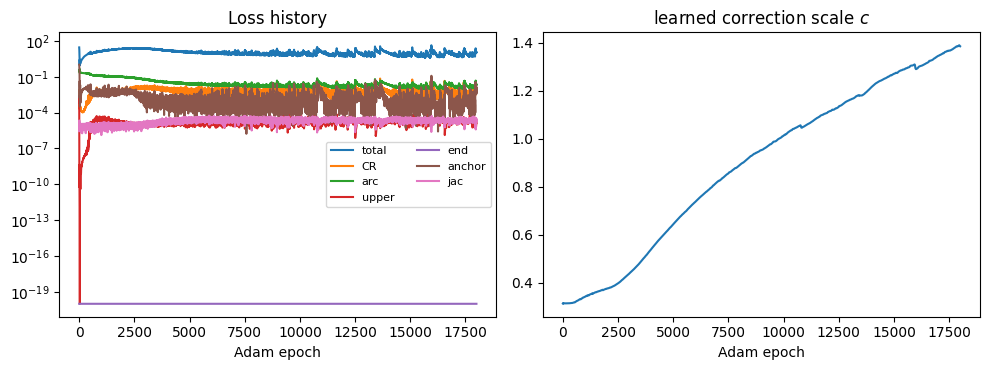

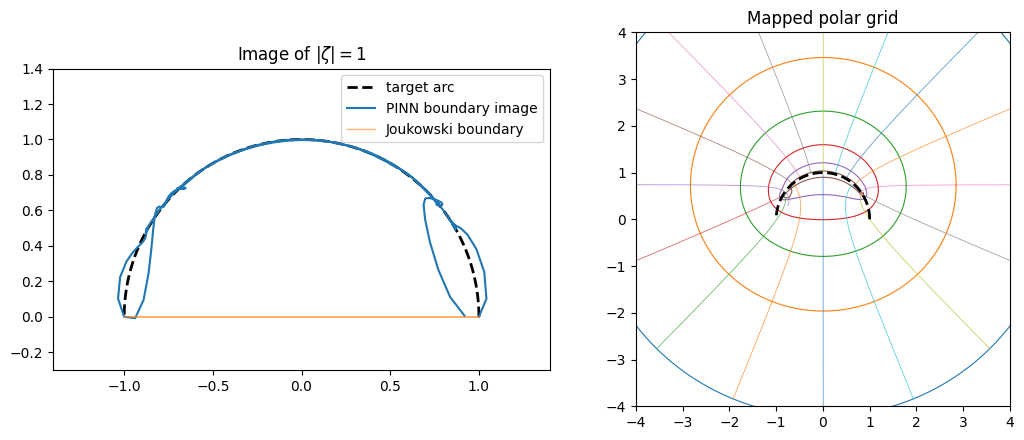

In [18]:
# Diagnostics
h = np.asarray(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for j, label in enumerate(["total","CR","arc","upper","end","anchor","jac"]):
    ax[0].semilogy(np.maximum(h[:,j], 1e-20), label=label)
ax[0].set_xlabel("Adam epoch")
ax[0].set_title("Loss history")
ax[0].legend(ncol=2, fontsize=8)
ax[1].plot(h[:,-1])
ax[1].set_xlabel("Adam epoch")
ax[1].set_title("learned correction scale $c$")
plt.tight_layout()
plt.show()

# Boundary image
with torch.no_grad():
    xy_b, t_b = sample_unit_circle(1200)
    uv_b = model(xy_b).cpu().numpy()
    xy_b_np = xy_b.cpu().numpy()
    gx, gy = model.joukowski(xy_b[:,0:1], xy_b[:,1:2])
    jou_b = torch.cat([gx, gy], dim=1).cpu().numpy()

th = np.linspace(0, np.pi, 500)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(np.cos(th), np.sin(th), "k--", lw=2, label="target arc")
ax[0].plot(uv_b[:,0], uv_b[:,1], lw=1.5, label="PINN boundary image")
ax[0].plot(jou_b[:,0], jou_b[:,1], lw=1, alpha=0.6, label="Joukowski boundary")
ax[0].set_aspect("equal")
ax[0].set_xlim(-1.4,1.4); ax[0].set_ylim(-0.3,1.4)
ax[0].legend(); ax[0].set_title("Image of $|\zeta|=1$")

# Map several circles and radial lines to inspect global geometry.
with torch.no_grad():
    for r in [0.10,0.18,0.30,0.50,0.75,0.95]:
        t = torch.linspace(0, 2*np.pi, 800, device=device).view(-1,1)
        xy = torch.cat([r*torch.cos(t), r*torch.sin(t)], dim=1)
        w = model(xy).cpu().numpy()
        ax[1].plot(w[:,0], w[:,1], lw=0.8)
    for t0 in np.linspace(0, 2*np.pi, 16, endpoint=False):
        r = torch.linspace(0.10,0.98,500,device=device).view(-1,1)
        xy = torch.cat([r*torch.cos(torch.tensor(t0,device=device))*torch.ones_like(r),
                        r*torch.sin(torch.tensor(t0,device=device))*torch.ones_like(r)],dim=1)
        w = model(xy).cpu().numpy()
        ax[1].plot(w[:,0],w[:,1],lw=0.6,alpha=0.7)
ax[1].plot(np.cos(th),np.sin(th),"k--",lw=2)
ax[1].set_aspect("equal")
ax[1].set_title("Mapped polar grid")
ax[1].set_xlim(-4,4); ax[1].set_ylim(-4,4)
plt.tight_layout(); plt.show()


In [7]:
# Quantitative residuals on fresh points
xy = sample_punctured_disk(5000, requires_grad=True)
uv = model(xy); u,v = uv[:,0:1],uv[:,1:2]
gu = grad_scalar(u,xy); gv = grad_scalar(v,xy)
cr_rms = torch.sqrt(((gu[:,0:1]-gv[:,1:2]).square() + (gu[:,1:2]+gv[:,0:1]).square()).mean())
jac = gu[:,0:1]*gv[:,1:2]-gu[:,1:2]*gv[:,0:1]

xy_b,_ = sample_unit_circle(3000)
with torch.no_grad():
    wb = model(xy_b)
    radius_err = torch.sqrt(((wb[:,0]**2+wb[:,1]**2-1)**2).mean())
    min_imag = wb[:,1].min()

print(f"CR RMS                 : {cr_rms.item():.4e}")
print(f"boundary radius RMS    : {radius_err.item():.4e}")
print(f"minimum boundary Im(f) : {min_imag.item():.4e}")
print(f"minimum Jacobian       : {jac.min().item():.4e}")
print(f"correction scale c     : {model.c.item():.4e}")

# Save weights if desired
# torch.save(model.state_dict(), "joukowski_semicircle_pinn.pt")


CR RMS                 : 7.3730e-01
boundary radius RMS    : 2.6563e-02
minimum boundary Im(f) : -6.9486e-03
minimum Jacobian       : -3.0933e+00
correction scale c     : 2.6182e+00


## Remarks

1. **The boundary correspondence is not prescribed pointwise.**  This is deliberate.  A conformal map determines its own parameterisation of the two sides of the semicircular slit/arc.  Prescribing $(\cos t,|\sin t|)$ pointwise is generally incompatible with analyticity and with the chosen principal part at $\zeta=0$.
2. The Joukowski principal part is kept exact.  The neural network learns only a regular correction.
3. The two weak conditions $f(i)\approx i$ and $f(-i)\approx i$ are normalisation conditions.  If they bias the solution too strongly, set `W_ANCHOR = 0` or replace them by a different normalisation.
4. Training uses **CR-first** weights, `(z^2-1)N` (no `W_END`), boundary ramp `BC_WARMUP`, and penalties on **negative Jacobian**.
5. This boundary-value problem is hard for plain PINNs: if CR RMS stays above $\sim 0.1$, treat the notebook as a *qualitative* Joukowski-correction demo or switch to pointwise BC on the lower half (simpler `05_conformal_map_joukowski_semicycle.ipynb`).
